# Tome 0, Chapter 7: Linear Algebra, Revisited (Python companion)

Exercises first, solutions at the end. Computer-science threads: **PageRank** (an eigenvector that ranked the web),
**SVD image compression**, and **ill-conditioning** (why the Hilbert matrix breaks linear solvers).

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
rng = np.random.default_rng(0)

## Exercises

**P7.1 (★) Fibonacci by matrices.** Compute $F_n \bmod m$ via $M^n \bmod m$ with fast exponentiation (square-and-multiply on $2\times2$ integer matrices). Find the period of $F_n \bmod 10$ (the *Pisano period*), and the last 10 digits of $F_{10^{18}}$.

In [2]:
# Your code here


**P7.2 (★) Symbolic checks.** With SymPy, verify Vandermonde's formula for $n = 4$ symbolically, Cayley–Hamilton on a random $4\times4$ integer matrix, and $\chi_{AB} = \chi_{BA}$ for random singular $A$.

In [3]:
# Your code here


**P7.3 (★★) CS application: PageRank.** A random surfer on a web graph follows a random outgoing link with probability $0.85$ and jumps to a uniformly random page otherwise. The PageRank vector is the stationary distribution: the eigenvector for eigenvalue $1$ of the Google matrix $G = 0.85\,P + 0.15\,\frac1n J$. Compute it by **power iteration** on the small graph given in the solution and compare with `np.linalg.eig`.

In [4]:
# Your code here


**P7.4 (★★) CS application: compressing an image with the SVD.** Every real matrix factors as $A = U\Sigma V^{\mathsf T}$ (the spectral theorem applied to $A^{\mathsf T}A$). Keeping the $k$ largest singular values gives the best rank-$k$ approximation. Build a $256\times256$ greyscale image, and show its rank-$k$ approximations for $k = 1, 5, 20, 50$ with the storage they need.

In [5]:
# Your code here


**P7.5 (★★★) The Hilbert matrix breaks solvers.** For $n = 4, 8, 12, 16$, solve $H_nx = H_n\mathbf 1$ in float64 (the exact solution is $\mathbf 1$) and print the error and the condition number. Then solve exactly with SymPy rationals. What do you conclude?

In [6]:
# Your code here


---
## Solutions

### P7.1

In [7]:
def mat_mult(A, B, m):
    return [[(A[0][0] * B[0][0] + A[0][1] * B[1][0]) % m, (A[0][0] * B[0][1] + A[0][1] * B[1][1]) % m],
            [(A[1][0] * B[0][0] + A[1][1] * B[1][0]) % m, (A[1][0] * B[0][1] + A[1][1] * B[1][1]) % m]]

def mat_pow(A, n, m):
    R = [[1, 0], [0, 1]]
    while n:
        if n & 1:
            R = mat_mult(R, A, m)
        A = mat_mult(A, A, m)
        n >>= 1
    return R

def fib_mod(n, m):
    return mat_pow([[1, 1], [1, 0]], n, m)[0][1]

assert [fib_mod(n, 10**9) for n in range(10)] == [0, 1, 1, 2, 3, 5, 8, 13, 21, 34]
period = next(k for k in range(1, 1000) if fib_mod(k, 10) == 0 and fib_mod(k + 1, 10) == 1)
print("Pisano period mod 10:", period)
print("last 10 digits of F_(10^18):", str(fib_mod(10**18, 10**10)).zfill(10))

Pisano period mod 10: 60
last 10 digits of F_(10^18): 9560546875


### P7.2

In [8]:
xs = sp.symbols("x1:5")
V = sp.Matrix(4, 4, lambda i, j: xs[i] ** j)
print("Vandermonde:", sp.factor(V.det()))
assert sp.expand(V.det() - sp.prod([xs[j] - xs[i] for i in range(4) for j in range(i + 1, 4)])) == 0

A = sp.Matrix(rng.integers(-5, 6, size=(4, 4)).tolist())
lam = sp.symbols("lam")
coeffs = A.charpoly(lam).all_coeffs()
assert sum((c * A ** (len(coeffs) - 1 - k) for k, c in enumerate(coeffs)), sp.zeros(4)) == sp.zeros(4)
print("Cayley-Hamilton holds")

A = sp.Matrix([[1, 2, 3], [2, 4, 6], [0, 1, 1]])   # rank 2, singular
B = sp.Matrix(rng.integers(-3, 4, size=(3, 3)).tolist())
assert (A * B).charpoly(lam) == (B * A).charpoly(lam)
print("chi_AB = chi_BA with A singular:", (A * B).charpoly(lam).as_expr())

Vandermonde: (x1 - x2)*(x1 - x3)*(x1 - x4)*(x2 - x3)*(x2 - x4)*(x3 - x4)
Cayley-Hamilton holds
chi_AB = chi_BA with A singular: lam**3 + 15*lam**2 - 10*lam


### P7.3

In [9]:
links = {0: [1, 2], 1: [2], 2: [0], 3: [0, 2], 4: [3, 5], 5: [4], 6: [2, 5]}
n = len(links)
P = np.zeros((n, n))
for i, outs in links.items():
    for j in outs:
        P[j, i] = 1 / len(outs)          # column i = where the surfer goes from page i
G = 0.85 * P + 0.15 / n * np.ones((n, n))

r = np.ones(n) / n
for it in range(100):
    r_new = G @ r
    if np.abs(r_new - r).sum() < 1e-12:
        break
    r = r_new
print(f"power iteration converged in {it} steps:", np.round(r, 4))

w, v = np.linalg.eig(G)
k = np.argmin(np.abs(w - 1))
print("eigenvector for 1:              ", np.round(np.real(v[:, k] / v[:, k].sum()), 4))
print("ranking (best first):", [int(i) for i in np.argsort(-r)])

power iteration converged in 54 steps: [0.3151 0.1553 0.319  0.053  0.0742 0.0621 0.0214]
eigenvector for 1:               [0.3151 0.1553 0.319  0.053  0.0742 0.0621 0.0214]
ranking (best first): [2, 0, 1, 4, 5, 3, 6]


$G$ has positive entries and columns summing to 1, so by the Perron–Frobenius theorem (Tome 3, Markov chains) the eigenvalue $1$ is simple and all other eigenvalues have modulus at most $0.85$: power iteration converges geometrically at rate $0.85$, whatever the size of the web.

### P7.4

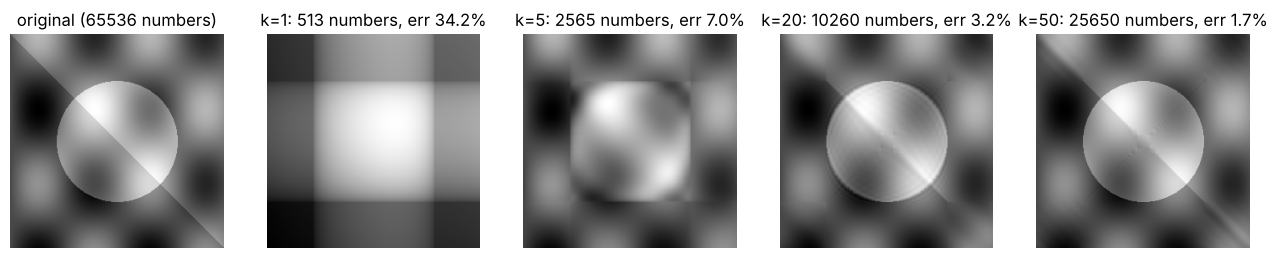

In [10]:
y, x = np.mgrid[0:256, 0:256] / 256
img = (np.sin(12 * x) * np.cos(9 * y) + ((x - 0.5)**2 + (y - 0.5)**2 < 0.08) + 0.5 * (x > y)) 
img = (img - img.min()) / (img.max() - img.min())
U, s, Vt = np.linalg.svd(img)
fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
axes[0].imshow(img, cmap="grey"); axes[0].set_title("original (65536 numbers)")
for ax, k in zip(axes[1:], [1, 5, 20, 50]):
    approx = U[:, :k] * s[:k] @ Vt[:k]
    err = np.linalg.norm(img - approx) / np.linalg.norm(img)
    ax.imshow(approx, cmap="grey"); ax.set_title(f"k={k}: {k * (256 * 2 + 1)} numbers, err {err:.1%}")
for ax in axes: ax.axis("off")
plt.show()

### P7.5

In [11]:
for n in [4, 8, 12, 16]:
    H = np.array([[1 / (i + j - 1) for j in range(1, n + 1)] for i in range(1, n + 1)])
    x = np.linalg.solve(H, H @ np.ones(n))
    print(f"n = {n:2d}: cond = {np.linalg.cond(H):.1e}, max error = {np.abs(x - 1).max():.1e}")
n = 16
Hq = sp.Matrix(n, n, lambda i, j: sp.Rational(1, i + j + 1))
xq = Hq.LUsolve(Hq * sp.ones(n, 1))
print("exact rational solve, n = 16:", set(xq))
print("det H_16 =", sp.N(Hq.det(), 5))

n =  4: cond = 1.6e+04, max error = 5.4e-14
n =  8: cond = 1.5e+10, max error = 1.3e-07
n = 12: cond = 1.6e+16, max error = 2.8e-01
n = 16: cond = 3.1e+17, max error = 4.4e+00
exact rational solve, n = 16: {1}
det H_16 = 1.4191e-142


Float64 carries about 16 digits, while the condition number of $H_{16}$ is about $10^{22}$ (NumPy cannot even estimate it correctly), so every digit of the answer is lost. $\det H_n$ is positive (Exercise 7.7) but about $10^{-142}$ for $n = 16$: positive definite and still numerically singular. Exact rational arithmetic has no such problem, at a higher cost.